Compares results from scans taken alternating Ushots and Tshots

In [51]:
analysis_folder = r"F:\Analysis Scripts\analysis"

import sys
if analysis_folder not in sys.path:
	sys.path.append(analysis_folder)

import numpy as np
import matplotlib.pyplot as plt
from data_class import Data
from library import MW_styles

In [53]:
scan = "2026-10-23_G"
fs = [f"{scan}_e_Ballistic.csv", f"{scan}_e_Unitary_NB54806.csv", f"{scan}_e_Unitary_NB73000.csv"]
b_dat, u_dat1, u_dat2 = [Data(f).data for f in fs]

F:\Data\2026\*\*\*\2026-10-23_G_e_Ballistic.csv
F:\Data\2026\*\*\*\2026-10-23_G_e_Unitary_NB54806.csv
F:\Data\2026\*\*\*\2026-10-23_G_e_Unitary_NB73000.csv


In [86]:
# tshots = b_dat[b_dat["p1"] > 5]
# ushots = u_dat[u_dat["p1"] < 5]

# t_shots_as_u = u_dat[u_dat["p1"] > 5] # t shots analyzed as u shots
# u_shots_as_t = b_dat[b_dat["p1"] < 5] # u shots analyzed as t shots

tshots = b_dat[b_dat["cycle"]%2 ==0]
ushots = u_dat2[u_dat2["cycle"]%2 != 0]

t_shots_as_u = u_dat2[u_dat2["cycle"]%2 ==0] # t shots analyzed as u shots
u_shots_as_t = b_dat[b_dat["cycle"]%2 != 0] # u shots analyzed as t shots

In [55]:
MW_styles[4]['marker'] = 'o'
MW_styles[5]['marker'] = 's'

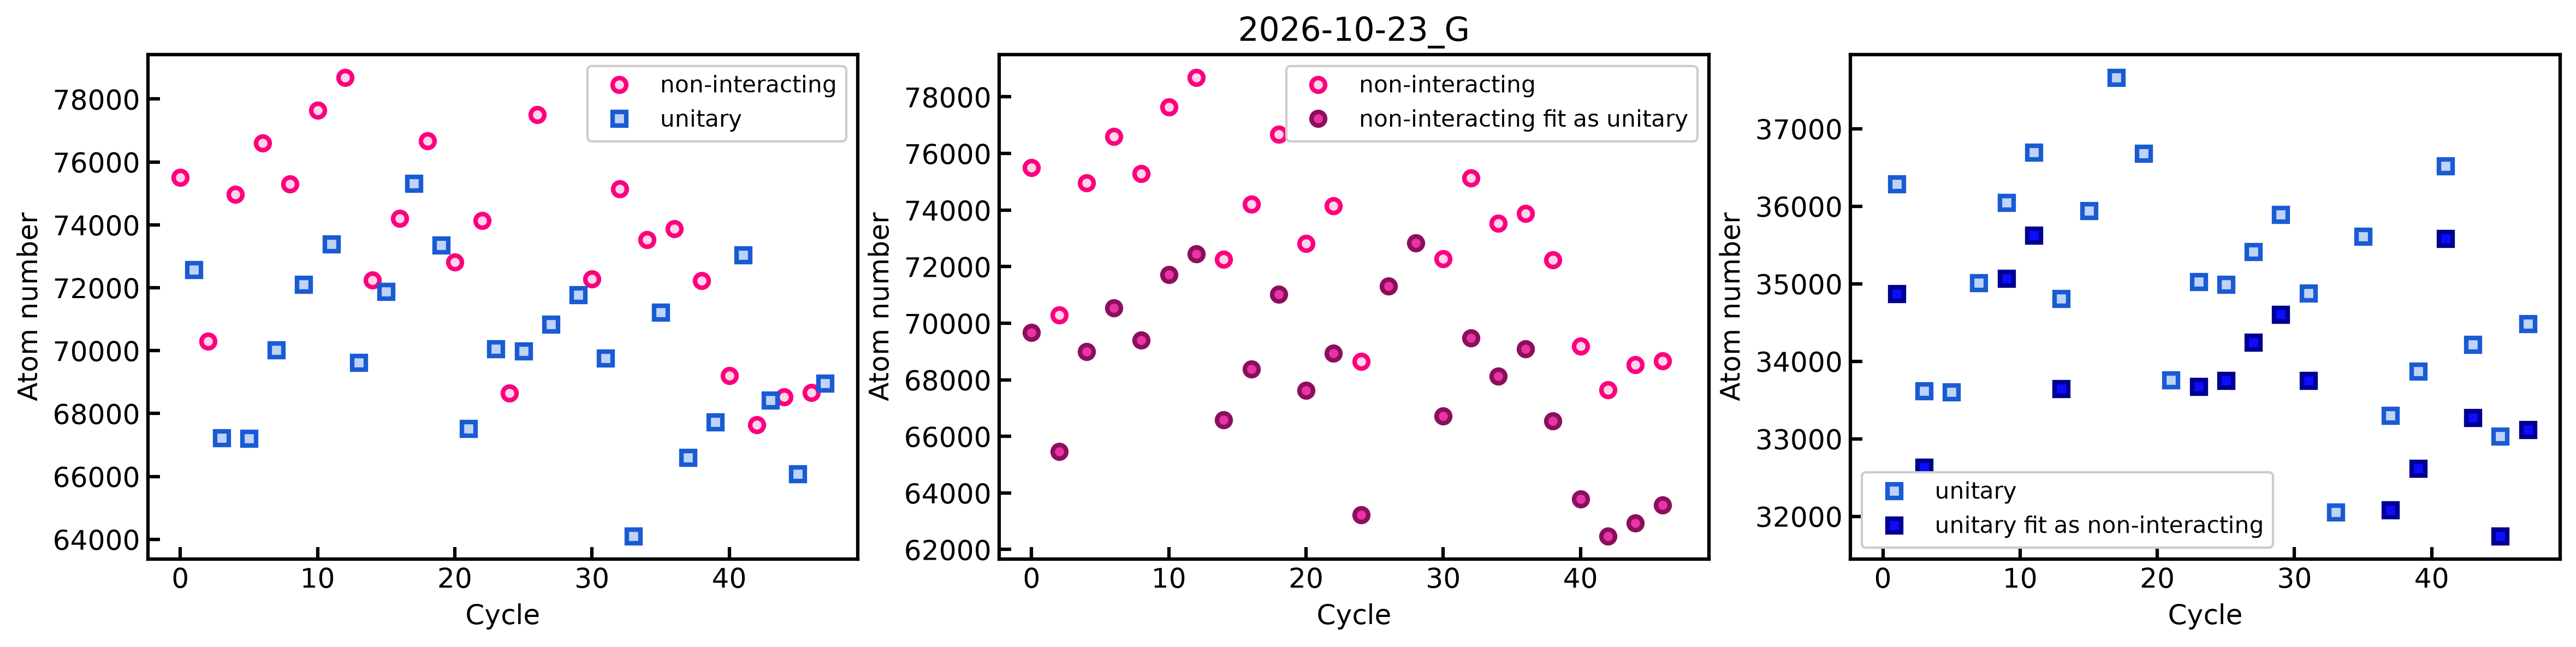

In [56]:
fig, axs = plt.subplots(1,3, figsize=(19, 4), sharex=True)
axs = axs.flatten()

axs[1].set_title(scan)

axs[0].plot(tshots.cycle, tshots["Li.nfit"], label="non-interacting", **MW_styles[0])
axs[0].plot(ushots.cycle, 2*ushots["N"], label="unitary", **MW_styles[1])

axs[1].plot(tshots.cycle, tshots["Li.nfit"], label="non-interacting", **MW_styles[0])
axs[1].plot(t_shots_as_u.cycle, t_shots_as_u["N"], label="non-interacting fit as unitary", **MW_styles[4])

axs[2].plot(ushots.cycle, ushots["N"], label="unitary", **MW_styles[1])
axs[2].plot(u_shots_as_t.cycle, u_shots_as_t["Li.nfit"], label="unitary fit as non-interacting", **MW_styles[5])

for ax in axs:
    ax.set_ylabel("Atom number")
    ax.set_xlabel("Cycle")
    ax.legend()

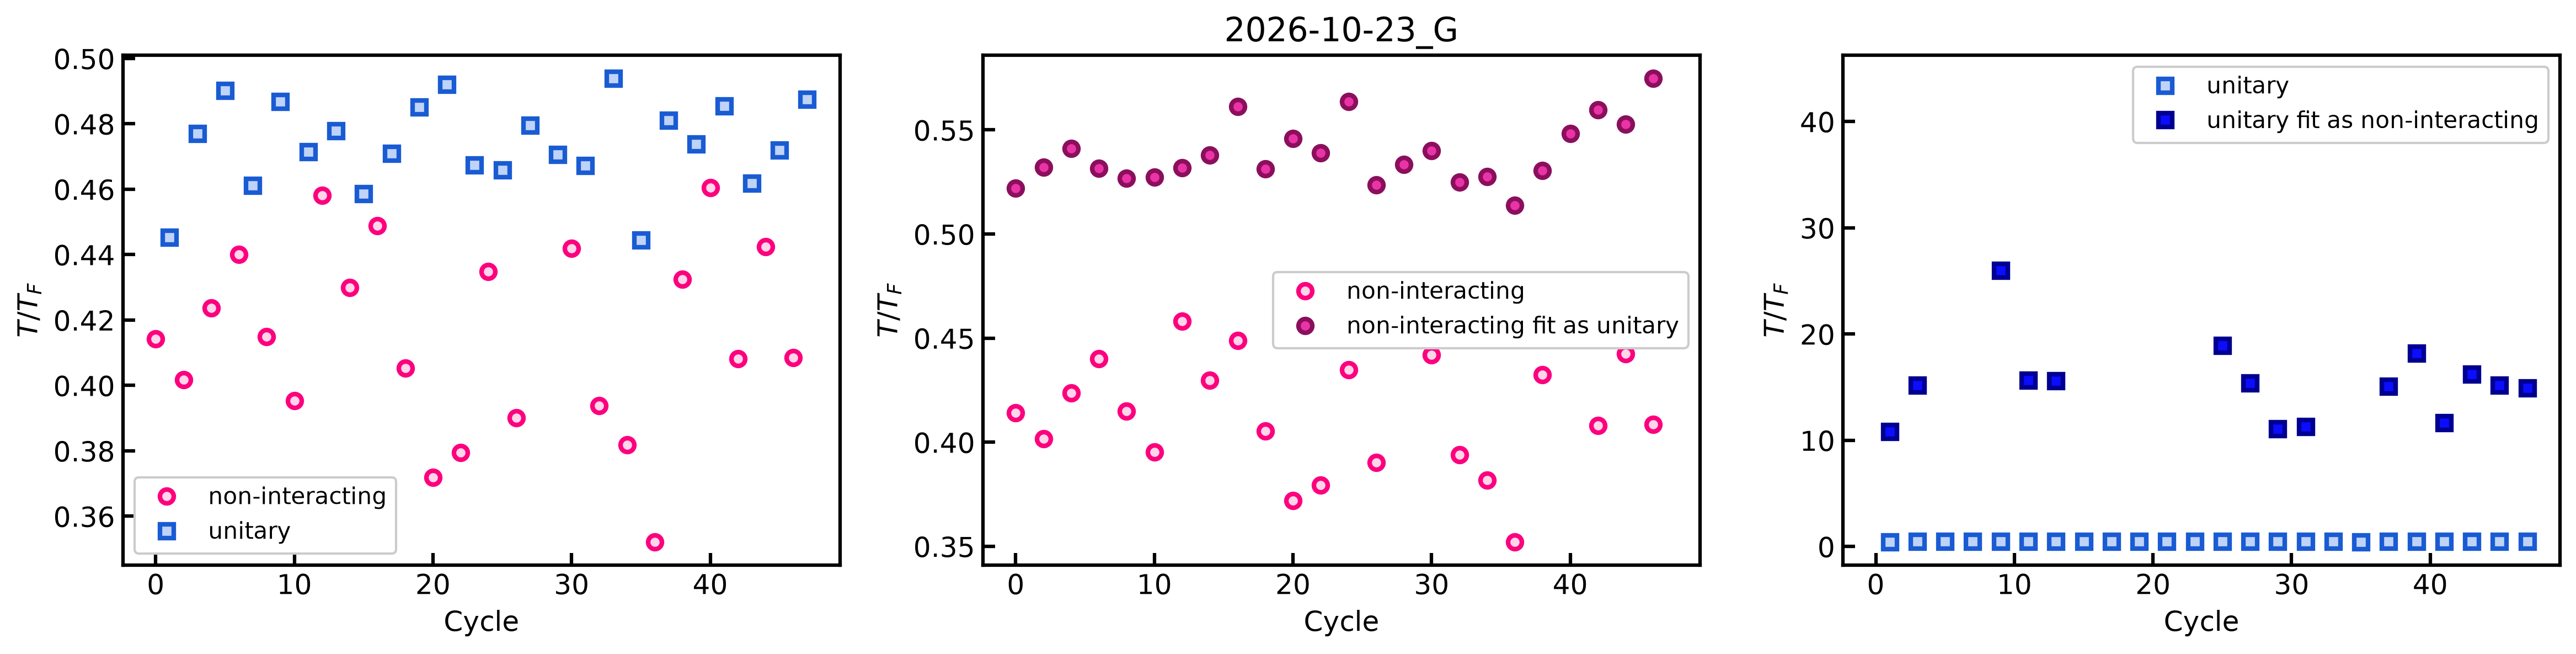

In [88]:
fig, axs = plt.subplots(1,3, figsize=(19, 4), sharex=True)

axs = axs.flatten()

axs[1].set_title(scan)

axs[0].plot(tshots.cycle, tshots["Li.ToTF"], label="non-interacting", **MW_styles[0])
axs[0].plot(ushots.cycle, ushots["ToTF"], label="unitary", **MW_styles[1])

axs[1].plot(tshots.cycle, tshots["Li.ToTF"], label="non-interacting", **MW_styles[0])
axs[1].plot(t_shots_as_u.cycle, t_shots_as_u["ToTF"], label="non-interacting fit as unitary", **MW_styles[4])

axs[2].plot(ushots.cycle, ushots["ToTF"], label="unitary", **MW_styles[1])
axs[2].plot(u_shots_as_t.cycle, u_shots_as_t["Li.ToTF"], label="unitary fit as non-interacting", **MW_styles[5])

for ax in axs:
    ax.set_ylabel("$T/T_F$")
    ax.set_xlabel("Cycle")
    ax.legend()

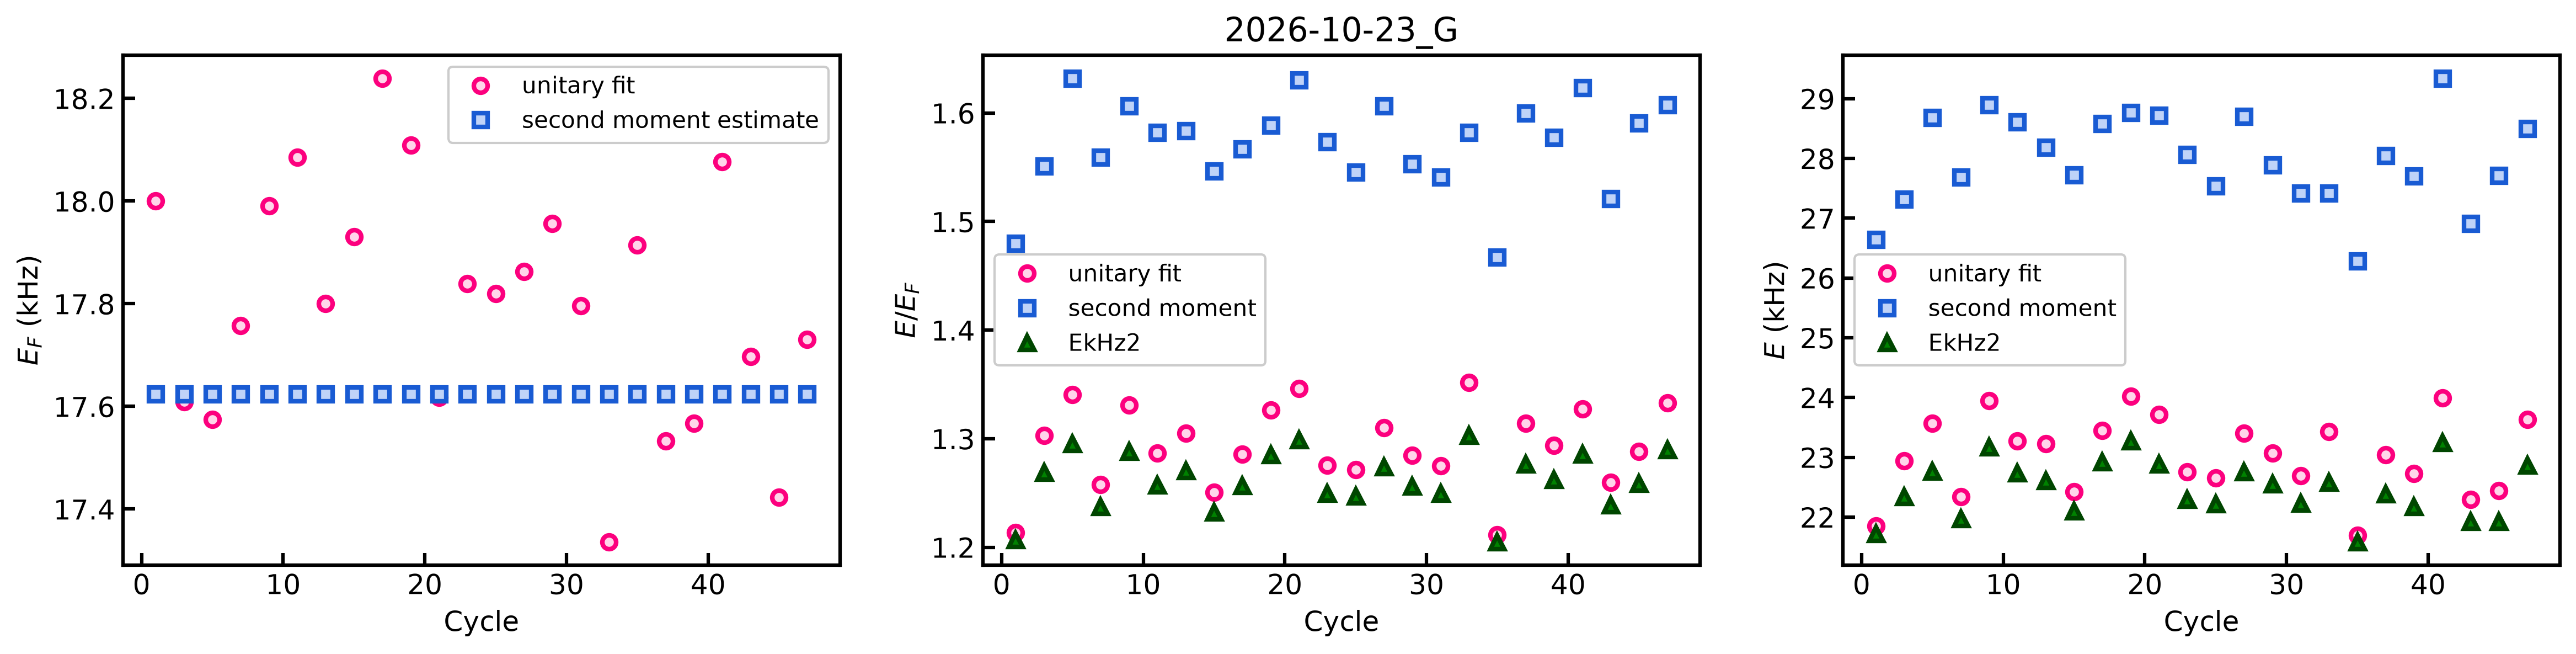

In [ ]:
fig, axs = plt.subplots(1,3, figsize=(19, 4), sharex=True)

axs = axs.flatten()

axs[1].set_title(scan)

axs[0].plot(ushots.cycle, ushots["EFkHz"], label="unitary fit", **MW_styles[0])
axs[0].plot(ushots.cycle, ushots["EFkHzEst"], label="second moment estimate", **MW_styles[1])
axs[0].set_ylabel("$E_F$ (kHz)")

axs[1].plot(ushots.cycle, ushots["ENoEF"], label="unitary fit", **MW_styles[0])
axs[1].plot(ushots.cycle, ushots["smomEoEF"], label="second moment", **MW_styles[1])
axs[1].plot(ushots.cycle, ushots["ENoEF2"], label="EkHz2", **MW_styles[2])
axs[1].set_ylabel("$E/E_F$")

axs[2].plot(ushots.cycle, ushots["EkHz"], label="unitary fit", **MW_styles[0])
axs[2].plot(ushots.cycle, ushots["smomEkHz"], label="second moment", **MW_styles[1])
axs[2].plot(ushots.cycle, ushots["EkHz2"], label="EkHz2", **MW_styles[2])
axs[2].set_ylabel("$E$ (kHz)")

for ax in axs:
    ax.set_xlabel("Cycle")
    ax.legend()

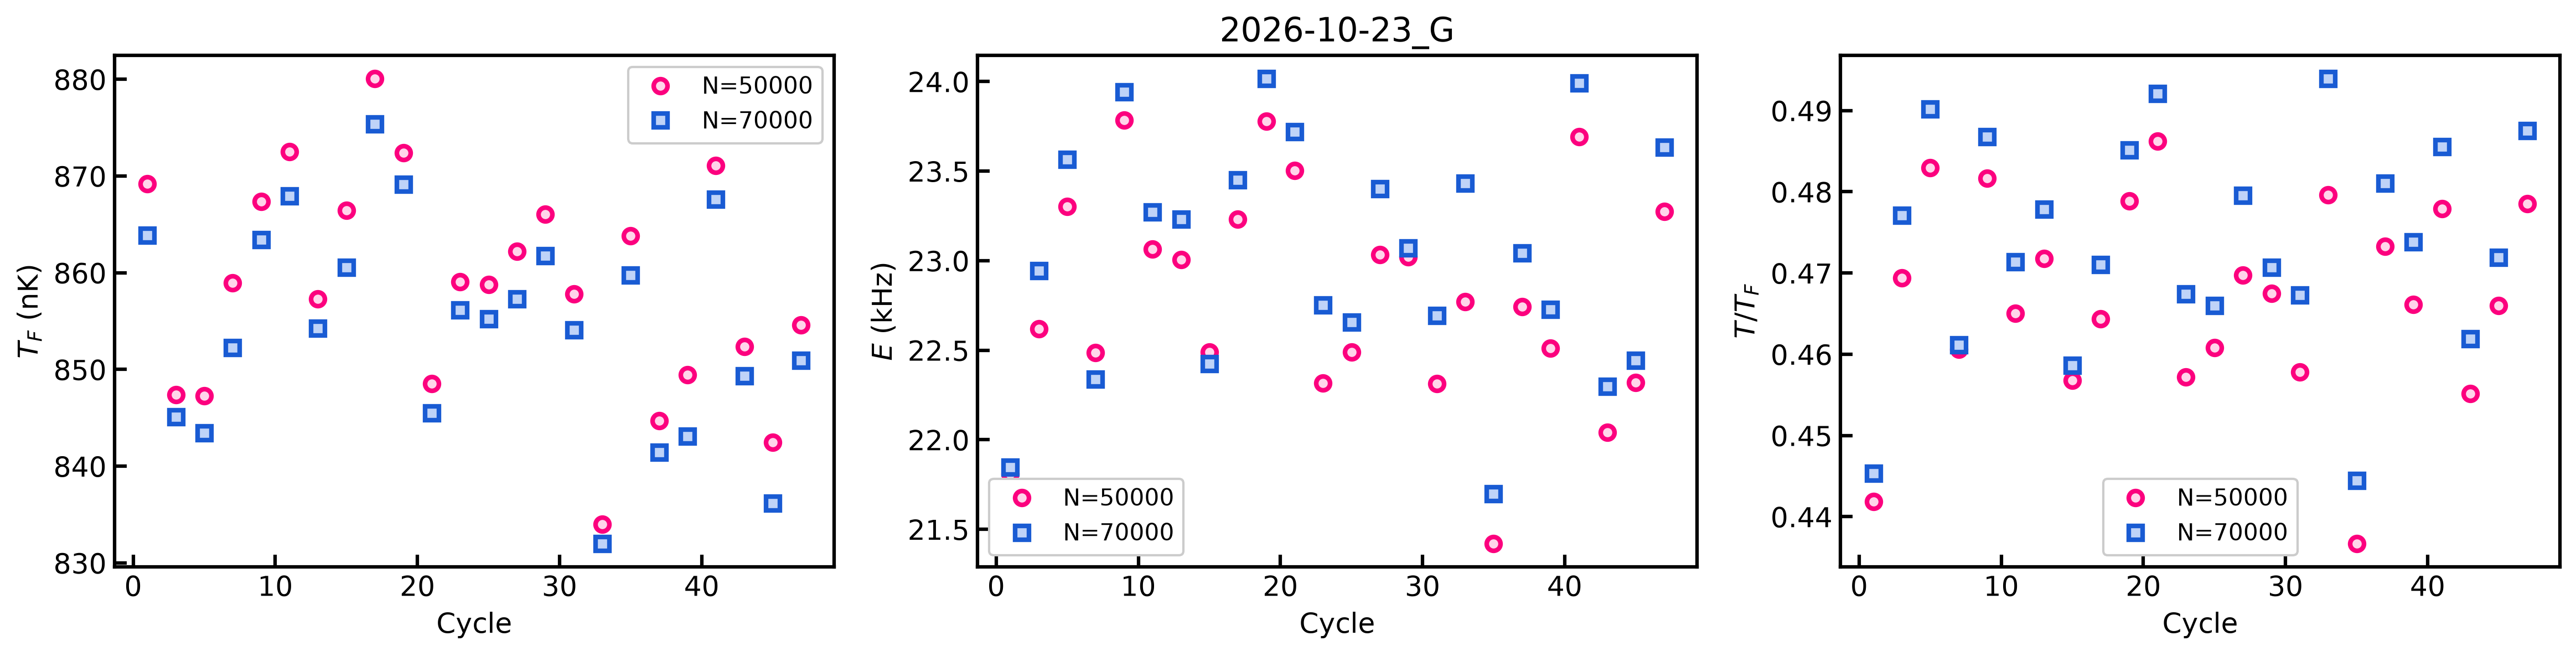

In [102]:
ushots1 = u_dat1[u_dat1["cycle"]%2 != 0]
ushots2 = u_dat2[u_dat2["cycle"]%2 != 0]

fig, axs = plt.subplots(1,3, figsize=(19, 4), sharex=True)
axs = axs.flatten()
axs[1].set_title(scan)

axs[0].plot(ushots1.cycle, ushots1["TF"]*1e9, label="N=50000", **MW_styles[0])
axs[0].plot(ushots2.cycle, ushots2["TF"]*1e9, label="N=70000", **MW_styles[1])
axs[0].set_ylabel("$T_F$ (nK)")

axs[1].plot(ushots1.cycle, ushots1["EkHz"], label="N=50000", **MW_styles[0])
axs[1].plot(ushots2.cycle, ushots2["EkHz"], label="N=70000", **MW_styles[1])
axs[1].set_ylabel("$E$ (kHz)")

axs[2].plot(ushots1.cycle, ushots1["ToTF"], label="N=50000", **MW_styles[0])
axs[2].plot(ushots2.cycle, ushots2["ToTF"], label="N=70000", **MW_styles[1])
axs[2].set_ylabel("$T/T_F$")

for ax in axs:
    ax.set_xlabel("Cycle")
    ax.legend()